In [1]:
import torch
import torchvision
from torchvision import datasets

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

PyTorch version: 2.11.0+cu128
Torchvision version: 0.26.0+cu128


In [2]:
train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True
)

print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))

100%|██████████| 170M/170M [52:11<00:00, 54.5kB/s] 


Training samples: 50000
Test samples: 10000


In [3]:
image, label = train_dataset[0]

print("Image type:", type(image))
print("Label:", label)
print("Image size:", image.size)

Image type: <class 'PIL.Image.Image'>
Label: 6
Image size: (32, 32)


In [4]:
classes = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

print("Class:", classes[label])

Class: frog


In [5]:
from torchvision import transforms

to_tensor = transforms.ToTensor()

image_tensor = to_tensor(image)

print("Tensor shape:", image_tensor.shape)
print("Tensor dtype:", image_tensor.dtype)
print("Minimum value:", image_tensor.min().item())
print("Maximum value:", image_tensor.max().item())

Tensor shape: torch.Size([3, 32, 32])
Tensor dtype: torch.float32
Minimum value: 0.0
Maximum value: 1.0


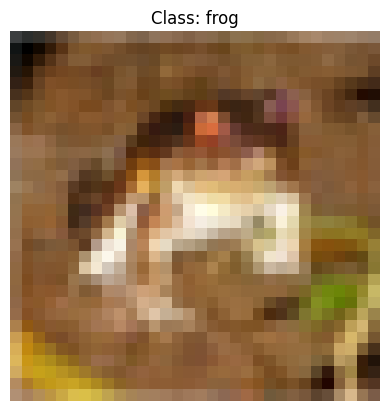

In [6]:
import matplotlib.pyplot as plt

plt.imshow(image)
plt.title(f"Class: {classes[label]}")
plt.axis("off");

In [7]:
print(image_tensor.shape)

print("\nRed channel:")
print(image_tensor[0])

print("\nGreen channel:")
print(image_tensor[1])

print("\nBlue channel:")
print(image_tensor[2])

torch.Size([3, 32, 32])

Red channel:
tensor([[0.2314, 0.1686, 0.1961,  ..., 0.6196, 0.5961, 0.5804],
        [0.0627, 0.0000, 0.0706,  ..., 0.4824, 0.4667, 0.4784],
        [0.0980, 0.0627, 0.1922,  ..., 0.4627, 0.4706, 0.4275],
        ...,
        [0.8157, 0.7882, 0.7765,  ..., 0.6275, 0.2196, 0.2078],
        [0.7059, 0.6784, 0.7294,  ..., 0.7216, 0.3804, 0.3255],
        [0.6941, 0.6588, 0.7020,  ..., 0.8471, 0.5922, 0.4824]])

Green channel:
tensor([[0.2431, 0.1804, 0.1882,  ..., 0.5176, 0.4902, 0.4863],
        [0.0784, 0.0000, 0.0314,  ..., 0.3451, 0.3255, 0.3412],
        [0.0941, 0.0275, 0.1059,  ..., 0.3294, 0.3294, 0.2863],
        ...,
        [0.6667, 0.6000, 0.6314,  ..., 0.5216, 0.1216, 0.1333],
        [0.5451, 0.4824, 0.5647,  ..., 0.5804, 0.2431, 0.2078],
        [0.5647, 0.5059, 0.5569,  ..., 0.7216, 0.4627, 0.3608]])

Blue channel:
tensor([[0.2471, 0.1765, 0.1686,  ..., 0.4235, 0.4000, 0.4039],
        [0.0784, 0.0000, 0.0000,  ..., 0.2157, 0.1961, 0.2235],
       

In [8]:
from torchvision import transforms, datasets

transform = transforms.ToTensor()

train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    transform=transform,
    download=True
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    transform=transform,
    download=True
)

In [9]:
image, label = train_dataset[0]

print("Image type:", type(image))
print("Image shape:", image.shape)
print("Label:", label)
print("Class:", classes[label])

Image type: <class 'torch.Tensor'>
Image shape: torch.Size([3, 32, 32])
Label: 6
Class: frog


In [10]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Test batches:", len(test_loader))

Training batches: 782
Test batches: 157


In [11]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Images dtype:", images.dtype)
print("Labels dtype:", labels.dtype)

Images shape: torch.Size([64, 3, 32, 32])
Labels shape: torch.Size([64])
Images dtype: torch.float32
Labels dtype: torch.int64


In [12]:
from collections import Counter

train_labels = [label for _, label in train_dataset]

counts = Counter(train_labels)

for class_id, count in sorted(counts.items()):
    print(f"{class_id}: {classes[class_id]:10s} → {count}")

0: airplane   → 5000
1: automobile → 5000
2: bird       → 5000
3: cat        → 5000
4: deer       → 5000
5: dog        → 5000
6: frog       → 5000
7: horse      → 5000
8: ship       → 5000
9: truck      → 5000


In [13]:
from torch.utils.data import random_split

train_size = 45_000
val_size = 5_000

generator = torch.Generator().manual_seed(42)

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size],
    generator=generator
)

print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))
print("Test samples:", len(test_dataset))

Training samples: 45000
Validation samples: 5000
Test samples: 10000


In [14]:
train_loader = DataLoader(
    train_subset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 704
Validation batches: 79
Test batches: 157


In [15]:
train_images, train_labels = next(iter(train_loader))
val_images, val_labels = next(iter(val_loader))
test_images, test_labels = next(iter(test_loader))

print("Train:")
print("  Images:", train_images.shape)
print("  Labels:", train_labels.shape)

print("\nValidation:")
print("  Images:", val_images.shape)
print("  Labels:", val_labels.shape)

print("\nTest:")
print("  Images:", test_images.shape)
print("  Labels:", test_labels.shape)

Train:
  Images: torch.Size([64, 3, 32, 32])
  Labels: torch.Size([64])

Validation:
  Images: torch.Size([64, 3, 32, 32])
  Labels: torch.Size([64])

Test:
  Images: torch.Size([64, 3, 32, 32])
  Labels: torch.Size([64])


In [16]:
import torch.nn as nn

baseline_cnn = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Flatten(),
    nn.Linear(64 * 8 * 8, 10)
)

print(baseline_cnn)

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=4096, out_features=10, bias=True)
)


In [17]:
output = baseline_cnn(train_images)

print("Input shape:", train_images.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([64, 3, 32, 32])
Output shape: torch.Size([64, 10])


In [18]:
total_params = sum(p.numel() for p in baseline_cnn.parameters())

print("Total parameters:", total_params)

Total parameters: 60362


In [19]:
for name, param in baseline_cnn.named_parameters():
    print(name, param.shape, param.numel())

0.weight torch.Size([32, 3, 3, 3]) 864
0.bias torch.Size([32]) 32
3.weight torch.Size([64, 32, 3, 3]) 18432
3.bias torch.Size([64]) 64
7.weight torch.Size([10, 4096]) 40960
7.bias torch.Size([10]) 10


In [20]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

baseline_cnn = baseline_cnn.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(
    baseline_cnn.parameters(),
    lr=0.01
)

print("Device:", device)
print("Model device:", next(baseline_cnn.parameters()).device)

Device: cuda
Model device: cuda:0


In [21]:
# Get one batch
images, labels = next(iter(train_loader))

# Move data to GPU
images = images.to(device)
labels = labels.to(device)

# 1. Clear old gradients
optimizer.zero_grad()

# 2. Forward pass
outputs = baseline_cnn(images)

# 3. Calculate loss
loss = criterion(outputs, labels)

# 4. Backpropagation
loss.backward()

# 5. Update weights
optimizer.step()

print("Images:", images.shape)
print("Outputs:", outputs.shape)
print("Loss:", loss.item())

Images: torch.Size([64, 3, 32, 32])
Outputs: torch.Size([64, 10])
Loss: 2.300774574279785


In [22]:
print("Conv1 weight gradient shape:",
      baseline_cnn[0].weight.grad.shape)

print("Conv1 weight gradient mean:",
      baseline_cnn[0].weight.grad.mean().item())

print("Conv1 weight gradient std:",
      baseline_cnn[0].weight.grad.std().item())

print("Linear weight gradient shape:",
      baseline_cnn[7].weight.grad.shape)

print("Linear weight gradient mean:",
      baseline_cnn[7].weight.grad.mean().item())

Conv1 weight gradient shape: torch.Size([32, 3, 3, 3])
Conv1 weight gradient mean: -0.0003269904409535229
Conv1 weight gradient std: 0.0018027343321591616
Linear weight gradient shape: torch.Size([10, 4096])
Linear weight gradient mean: -5.696676463884387e-11


In [23]:
epochs = 10

for epoch in range(epochs):

    # -----------------
    # Training
    # -----------------
    baseline_cnn.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = baseline_cnn(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # -----------------
    # Validation
    # -----------------
    baseline_cnn.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = baseline_cnn(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    print(
        f"Epoch {epoch+1:2d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch  1/10 | Train Loss: 2.0968 | Train Acc: 0.2461 | Val Loss: 1.9606 | Val Acc: 0.3042
Epoch  2/10 | Train Loss: 1.8467 | Train Acc: 0.3570 | Val Loss: 1.8856 | Val Acc: 0.3238
Epoch  3/10 | Train Loss: 1.6877 | Train Acc: 0.4118 | Val Loss: 1.7946 | Val Acc: 0.3600
Epoch  4/10 | Train Loss: 1.5666 | Train Acc: 0.4505 | Val Loss: 1.8895 | Val Acc: 0.3028
Epoch  5/10 | Train Loss: 1.4720 | Train Acc: 0.4837 | Val Loss: 1.5464 | Val Acc: 0.4310
Epoch  6/10 | Train Loss: 1.4046 | Train Acc: 0.5066 | Val Loss: 1.6644 | Val Acc: 0.4094
Epoch  7/10 | Train Loss: 1.3551 | Train Acc: 0.5257 | Val Loss: 1.3957 | Val Acc: 0.5038
Epoch  8/10 | Train Loss: 1.3123 | Train Acc: 0.5425 | Val Loss: 1.3765 | Val Acc: 0.5014
Epoch  9/10 | Train Loss: 1.2765 | Train Acc: 0.5559 | Val Loss: 1.3288 | Val Acc: 0.5290
Epoch 10/10 | Train Loss: 1.2422 | Train Acc: 0.5687 | Val Loss: 1.3111 | Val Acc: 0.5358


In [24]:
baseline_cnn.eval()

test_loss = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = baseline_cnn(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        test_correct += (predictions == labels).sum().item()
        test_total += labels.size(0)

test_loss /= test_total
test_acc = test_correct / test_total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

Test Loss: 1.2858
Test Accuracy: 0.5452
Test Accuracy: 54.52%


In [25]:
from sklearn.metrics import confusion_matrix

baseline_cnn.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = baseline_cnn(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_predictions)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[765  16  19   6  44   3  13   7  99  28]
 [ 76 654   3   6  24   2  13   9  77 136]
 [127  15 269  44 328  39  71  51  35  21]
 [ 61  11  54 315 250  84 108  36  40  41]
 [ 61   6  39  29 702  15  60  54  26   8]
 [ 41   4  93 162 210 280  58  92  40  20]
 [ 25  13  34  39 185   5 646  17  21  15]
 [ 59   5  32  44 197  31  23 558  15  36]
 [192  52   5   9  17   1   2  10 684  28]
 [ 84 150  12   6  28   5  23  25  88 579]]


In [26]:
print("Per-class accuracy:\n")

for class_id, class_name in enumerate(classes):
    correct = cm[class_id, class_id]
    total = cm[class_id].sum()
    accuracy = correct / total

    print(
        f"{class_id}: {class_name:10s} → "
        f"{accuracy:.2%}"
    )

Per-class accuracy:

0: airplane   → 76.50%
1: automobile → 65.40%
2: bird       → 26.90%
3: cat        → 31.50%
4: deer       → 70.20%
5: dog        → 28.00%
6: frog       → 64.60%
7: horse      → 55.80%
8: ship       → 68.40%
9: truck      → 57.90%


In [27]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# -----------------------------
# 1. Training augmentation
# -----------------------------

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor()
])

# -----------------------------
# 2. Clean transform
# -----------------------------

clean_transform = transforms.Compose([
    transforms.ToTensor()
])

# -----------------------------
# 3. Augmented training dataset
# -----------------------------

train_dataset_aug = datasets.CIFAR10(
    root="./data",
    train=True,
    transform=train_transform,
    download=True
)

# -----------------------------
# 4. Clean training dataset
#    Used only to create the
#    validation subset
# -----------------------------

train_dataset_clean = datasets.CIFAR10(
    root="./data",
    train=True,
    transform=clean_transform,
    download=True
)

# -----------------------------
# 5. Clean test dataset
# -----------------------------

test_dataset_clean = datasets.CIFAR10(
    root="./data",
    train=False,
    transform=clean_transform,
    download=True
)

# -----------------------------
# 6. Same reproducible split
# -----------------------------

train_size = 45_000
val_size = 5_000

generator = torch.Generator().manual_seed(42)

train_subset_aug, _ = torch.utils.data.random_split(
    train_dataset_aug,
    [train_size, val_size],
    generator=generator
)

# Reset the generator so we get
# the EXACT SAME indices for validation
generator = torch.Generator().manual_seed(42)

_, val_subset_clean = torch.utils.data.random_split(
    train_dataset_clean,
    [train_size, val_size],
    generator=generator
)

# -----------------------------
# 7. DataLoaders
# -----------------------------

train_loader_aug = DataLoader(
    train_subset_aug,
    batch_size=64,
    shuffle=True
)

val_loader_clean = DataLoader(
    val_subset_clean,
    batch_size=64,
    shuffle=False
)

test_loader_clean = DataLoader(
    test_dataset_clean,
    batch_size=64,
    shuffle=False
)

print("Training batches:", len(train_loader_aug))
print("Validation batches:", len(val_loader_clean))
print("Test batches:", len(test_loader_clean))

Training batches: 704
Validation batches: 79
Test batches: 157


In [28]:
image1, label1 = train_subset_aug[0]
image2, label2 = train_subset_aug[0]

print("Image shape:", image1.shape)
print("Label:", label1)
print("Same label:", label1 == label2)
print("Images identical:", torch.equal(image1, image2))

Image shape: torch.Size([3, 32, 32])
Label: 6
Same label: True
Images identical: False


In [29]:
import torch.nn as nn

aug_cnn = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Flatten(),
    nn.Linear(64 * 8 * 8, 10)
)

aug_cnn = aug_cnn.to(device)

criterion = nn.CrossEntropyLoss()

optimizer_aug = torch.optim.SGD(
    aug_cnn.parameters(),
    lr=0.01
)

print("Total parameters:", sum(p.numel() for p in aug_cnn.parameters()))

Total parameters: 60362


In [30]:
epochs = 10

for epoch in range(epochs):

    # =========================
    # TRAIN
    # =========================

    aug_cnn.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader_aug:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_aug.zero_grad()

        outputs = aug_cnn(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer_aug.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # =========================
    # VALIDATION
    # =========================

    aug_cnn.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader_clean:

            images = images.to(device)
            labels = labels.to(device)

            outputs = aug_cnn(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    print(
        f"Epoch {epoch+1:2d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch  1/10 | Train Loss: 2.1517 | Train Acc: 0.2148 | Val Loss: 2.0302 | Val Acc: 0.2664
Epoch  2/10 | Train Loss: 1.9274 | Train Acc: 0.3150 | Val Loss: 1.8973 | Val Acc: 0.3210
Epoch  3/10 | Train Loss: 1.7853 | Train Acc: 0.3674 | Val Loss: 1.9008 | Val Acc: 0.3288
Epoch  4/10 | Train Loss: 1.6779 | Train Acc: 0.4008 | Val Loss: 1.7548 | Val Acc: 0.3768
Epoch  5/10 | Train Loss: 1.6042 | Train Acc: 0.4285 | Val Loss: 1.7862 | Val Acc: 0.3890
Epoch  6/10 | Train Loss: 1.5561 | Train Acc: 0.4451 | Val Loss: 1.7020 | Val Acc: 0.3682
Epoch  7/10 | Train Loss: 1.5140 | Train Acc: 0.4579 | Val Loss: 1.4614 | Val Acc: 0.4852
Epoch  8/10 | Train Loss: 1.4795 | Train Acc: 0.4736 | Val Loss: 1.5070 | Val Acc: 0.4582
Epoch  9/10 | Train Loss: 1.4602 | Train Acc: 0.4788 | Val Loss: 1.4060 | Val Acc: 0.4972
Epoch 10/10 | Train Loss: 1.4329 | Train Acc: 0.4890 | Val Loss: 1.4826 | Val Acc: 0.4620


In [31]:
import torch.nn as nn

bn_cnn = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Flatten(),
    nn.Linear(64 * 8 * 8, 10)
)

bn_cnn = bn_cnn.to(device)

criterion_bn = nn.CrossEntropyLoss()

optimizer_bn = torch.optim.SGD(
    bn_cnn.parameters(),
    lr=0.01
)

print("Total parameters:",
      sum(p.numel() for p in bn_cnn.parameters()))

Total parameters: 60554


In [32]:
print(bn_cnn)

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Flatten(start_dim=1, end_dim=-1)
  (9): Linear(in_features=4096, out_features=10, bias=True)
)


In [33]:
images, labels = next(iter(train_loader))

images = images.to(device)

outputs = bn_cnn(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([64, 3, 32, 32])
Output shape: torch.Size([64, 10])


In [34]:
epochs = 10

for epoch in range(epochs):

    # =========================
    # Training
    # =========================
    bn_cnn.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_bn.zero_grad()

        outputs = bn_cnn(images)

        loss = criterion_bn(outputs, labels)

        loss.backward()

        optimizer_bn.step()

        train_loss += loss.item() * images.size(0)

        _, predicted = outputs.max(1)

        train_total += labels.size(0)
        train_correct += predicted.eq(labels).sum().item()

    train_loss /= train_total
    train_acc = train_correct / train_total


    # =========================
    # Validation
    # =========================
    bn_cnn.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = bn_cnn(images)

            loss = criterion_bn(outputs, labels)

            val_loss += loss.item() * images.size(0)

            _, predicted = outputs.max(1)

            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()

    val_loss /= val_total
    val_acc = val_correct / val_total


    print(
        f"Epoch {epoch+1:2d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch  1/10 | Train Loss: 1.5557 | Train Acc: 0.4650 | Val Loss: 3.1116 | Val Acc: 0.2640
Epoch  2/10 | Train Loss: 1.1514 | Train Acc: 0.5944 | Val Loss: 2.0551 | Val Acc: 0.3944
Epoch  3/10 | Train Loss: 1.0255 | Train Acc: 0.6407 | Val Loss: 1.8940 | Val Acc: 0.4292
Epoch  4/10 | Train Loss: 0.9402 | Train Acc: 0.6728 | Val Loss: 3.9521 | Val Acc: 0.2442
Epoch  5/10 | Train Loss: 0.8850 | Train Acc: 0.6920 | Val Loss: 3.2399 | Val Acc: 0.3176
Epoch  6/10 | Train Loss: 0.8379 | Train Acc: 0.7075 | Val Loss: 2.4378 | Val Acc: 0.3268
Epoch  7/10 | Train Loss: 0.7963 | Train Acc: 0.7248 | Val Loss: 1.3000 | Val Acc: 0.5786
Epoch  8/10 | Train Loss: 0.7627 | Train Acc: 0.7360 | Val Loss: 1.7883 | Val Acc: 0.5360
Epoch  9/10 | Train Loss: 0.7365 | Train Acc: 0.7465 | Val Loss: 2.0389 | Val Acc: 0.4640
Epoch 10/10 | Train Loss: 0.7104 | Train Acc: 0.7557 | Val Loss: 1.5645 | Val Acc: 0.5418


In [35]:
bn1 = bn_cnn[1]
bn2 = bn_cnn[5]

print("BN1 running mean:")
print(bn1.running_mean)

print("\nBN1 running variance:")
print(bn1.running_var)

print("\nBN2 running mean:")
print(bn2.running_mean)

print("\nBN2 running variance:")
print(bn2.running_var)

BN1 running mean:
tensor([-0.0477, -0.1998, -0.0319,  0.2952,  0.0477, -0.2820,  0.1591, -0.1423,
         0.2532,  0.0995, -0.1818,  0.2216,  0.0226, -0.3875, -0.1349, -0.0193,
         0.3469,  0.1438, -0.1233, -0.8334, -0.0685, -0.3878, -0.0142, -0.1620,
         0.1566,  0.0537,  0.0545,  0.0177,  0.1114, -0.1937, -0.1949, -0.0830],
       device='cuda:0')

BN1 running variance:
tensor([0.0083, 0.0129, 0.0226, 0.0405, 0.0132, 0.0184, 0.0147, 0.0462, 0.0061,
        0.0117, 0.0149, 0.0383, 0.0247, 0.0206, 0.0069, 0.0088, 0.0198, 0.0263,
        0.0169, 0.1034, 0.0097, 0.0257, 0.0199, 0.0195, 0.0282, 0.0270, 0.0186,
        0.0201, 0.0187, 0.0145, 0.0068, 0.0115], device='cuda:0')

BN2 running mean:
tensor([-2.9981e-02, -1.9490e-01, -2.3057e-01, -2.8339e-01, -1.0513e-01,
        -3.0267e-02, -3.1262e-01, -4.3672e-02, -2.2516e-01, -4.9536e-01,
        -1.4666e-01,  6.6891e-01, -8.1878e-01, -3.5106e-01,  1.8810e-01,
        -1.1536e-01, -5.6621e-02, -1.0599e-01,  3.3031e-02, -1.2325e-0

In [36]:
print("Training mode:", bn_cnn.training)

Training mode: False


In [37]:
images, labels = next(iter(val_loader))

images = images.to(device)
labels = labels.to(device)

# -------------------------
# Train mode
# -------------------------
bn_cnn.train()

with torch.no_grad():
    outputs_train = bn_cnn(images)

pred_train = outputs_train.argmax(dim=1)

# -------------------------
# Eval mode
# -------------------------
bn_cnn.eval()

with torch.no_grad():
    outputs_eval = bn_cnn(images)

pred_eval = outputs_eval.argmax(dim=1)

# -------------------------
# Compare
# -------------------------
train_acc = (pred_train == labels).float().mean().item()
eval_acc = (pred_eval == labels).float().mean().item()

different = (pred_train != pred_eval).sum().item()

print("Train-mode accuracy:", train_acc)
print("Eval-mode accuracy:", eval_acc)
print("Different predictions:", different, "out of", len(labels))

Train-mode accuracy: 0.546875
Eval-mode accuracy: 0.53125
Different predictions: 16 out of 64


In [38]:
print("Mean absolute output difference:",
      torch.mean(torch.abs(outputs_train - outputs_eval)).item())

print("\nFirst sample - train mode:")
print(outputs_train[0])

print("\nFirst sample - eval mode:")
print(outputs_eval[0])

Mean absolute output difference: 1.0776206254959106

First sample - train mode:
tensor([ 0.1595, -4.3753,  1.6303, -1.9571, -1.5852,  3.1395, -4.6851,  8.2092,
        -3.2366,  2.7279], device='cuda:0')

First sample - eval mode:
tensor([ 1.7536, -2.6404,  1.9559, -3.0125, -2.4352,  2.4115, -7.1477,  8.8383,
        -3.3972,  3.4699], device='cuda:0')


In [39]:
import copy

# Fresh BatchNorm CNN
checkpoint_cnn = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Flatten(),
    nn.Linear(64 * 8 * 8, 10)
).to(device)

criterion_checkpoint = nn.CrossEntropyLoss()

optimizer_checkpoint = torch.optim.SGD(
    checkpoint_cnn.parameters(),
    lr=0.01
)

best_val_acc = 0.0
best_epoch = 0
best_state = None

epochs = 10

for epoch in range(epochs):

    # =========================
    # Training
    # =========================
    checkpoint_cnn.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_checkpoint.zero_grad()

        outputs = checkpoint_cnn(images)

        loss = criterion_checkpoint(outputs, labels)

        loss.backward()

        optimizer_checkpoint.step()

        train_loss += loss.item() * images.size(0)

        _, predicted = outputs.max(1)

        train_total += labels.size(0)
        train_correct += predicted.eq(labels).sum().item()

    train_loss /= train_total
    train_acc = train_correct / train_total


    # =========================
    # Validation
    # =========================
    checkpoint_cnn.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = checkpoint_cnn(images)

            loss = criterion_checkpoint(outputs, labels)

            val_loss += loss.item() * images.size(0)

            _, predicted = outputs.max(1)

            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()

    val_loss /= val_total
    val_acc = val_correct / val_total


    # =========================
    # Checkpoint
    # =========================
    if val_acc > best_val_acc:

        best_val_acc = val_acc
        best_epoch = epoch + 1

        best_state = copy.deepcopy(
            checkpoint_cnn.state_dict()
        )

        print("  ⭐ New best model!")


    print(
        f"Epoch {epoch+1:2d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )


print("\nBest validation accuracy:", best_val_acc)
print("Best epoch:", best_epoch)

  ⭐ New best model!
Epoch  1/10 | Train Loss: 1.5453 | Train Acc: 0.4672 | Val Loss: 2.1047 | Val Acc: 0.4070
Epoch  2/10 | Train Loss: 1.1575 | Train Acc: 0.5935 | Val Loss: 5.1936 | Val Acc: 0.2034
  ⭐ New best model!
Epoch  3/10 | Train Loss: 1.0197 | Train Acc: 0.6425 | Val Loss: 1.4535 | Val Acc: 0.4994
  ⭐ New best model!
Epoch  4/10 | Train Loss: 0.9394 | Train Acc: 0.6746 | Val Loss: 1.5538 | Val Acc: 0.5094
Epoch  5/10 | Train Loss: 0.8780 | Train Acc: 0.6936 | Val Loss: 1.6885 | Val Acc: 0.4834
  ⭐ New best model!
Epoch  6/10 | Train Loss: 0.8350 | Train Acc: 0.7103 | Val Loss: 1.3781 | Val Acc: 0.5508
  ⭐ New best model!
Epoch  7/10 | Train Loss: 0.7996 | Train Acc: 0.7250 | Val Loss: 1.0927 | Val Acc: 0.6318
Epoch  8/10 | Train Loss: 0.7640 | Train Acc: 0.7361 | Val Loss: 1.4048 | Val Acc: 0.5524
Epoch  9/10 | Train Loss: 0.7341 | Train Acc: 0.7480 | Val Loss: 1.6909 | Val Acc: 0.5428
Epoch 10/10 | Train Loss: 0.7135 | Train Acc: 0.7547 | Val Loss: 2.6568 | Val Acc: 0.3666


In [40]:
checkpoint_cnn.load_state_dict(best_state)

print("Loaded best epoch:", best_epoch)
print("Best validation accuracy:", best_val_acc)

Loaded best epoch: 7
Best validation accuracy: 0.6318


In [41]:
checkpoint_cnn.eval()

test_loss = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():

    for images, labels in test_loader_clean:

        images = images.to(device)
        labels = labels.to(device)

        outputs = checkpoint_cnn(images)

        loss = criterion_checkpoint(outputs, labels)

        test_loss += loss.item() * images.size(0)

        _, predicted = outputs.max(1)

        test_total += labels.size(0)
        test_correct += predicted.eq(labels).sum().item()

test_loss /= test_total
test_acc = test_correct / test_total

print(f"Best Epoch: {best_epoch}")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

Best Epoch: 7
Test Loss: 1.0807
Test Accuracy: 0.6293
Test Accuracy: 62.93%


In [42]:
print("Current learning rate:")
print(optimizer_checkpoint.param_groups[0]["lr"])

Current learning rate:
0.01


In [43]:
scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer_checkpoint,
    step_size=3,
    gamma=0.1
)

print("Initial learning rate:",
      optimizer_checkpoint.param_groups[0]["lr"])

Initial learning rate: 0.01


In [44]:
for epoch in range(10):
    print(
        f"Epoch {epoch + 1}: "
        f"LR = {optimizer_checkpoint.param_groups[0]['lr']}"
    )

    scheduler.step()

Epoch 1: LR = 0.01
Epoch 2: LR = 0.01
Epoch 3: LR = 0.01
Epoch 4: LR = 0.001
Epoch 5: LR = 0.001
Epoch 6: LR = 0.001
Epoch 7: LR = 0.0001
Epoch 8: LR = 0.0001
Epoch 9: LR = 0.0001
Epoch 10: LR = 1e-05


/tmp/ipykernel_48/1878404273.py:7: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


In [45]:
optimizer_lr = torch.optim.SGD(
    checkpoint_cnn.parameters(),
    lr=0.01
)

scheduler_lr = torch.optim.lr_scheduler.StepLR(
    optimizer_lr,
    step_size=3,
    gamma=0.1
)

print("Initial LR:",
      optimizer_lr.param_groups[0]["lr"])

Initial LR: 0.01


In [46]:
lr_cnn = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),

    nn.Flatten(),
    nn.Linear(64 * 8 * 8, 10)
).to(device)

criterion_lr = nn.CrossEntropyLoss()

optimizer_lr = torch.optim.SGD(
    lr_cnn.parameters(),
    lr=0.01
)

scheduler_lr = torch.optim.lr_scheduler.StepLR(
    optimizer_lr,
    step_size=3,
    gamma=0.1
)

print("Parameters:",
      sum(p.numel() for p in lr_cnn.parameters()))

print("Initial LR:",
      optimizer_lr.param_groups[0]["lr"])

Parameters: 60554
Initial LR: 0.01


In [47]:
for epoch in range(10):

    # --------------------
    # Training
    # --------------------
    lr_cnn.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_lr.zero_grad()

        outputs = lr_cnn(images)
        loss = criterion_lr(outputs, labels)

        loss.backward()
        optimizer_lr.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total


    # --------------------
    # Validation
    # --------------------
    lr_cnn.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = lr_cnn(images)
            loss = criterion_lr(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total


    # Save LR BEFORE changing it
    current_lr = optimizer_lr.param_groups[0]["lr"]

    print(
        f"Epoch {epoch+1:2d} | "
        f"LR {current_lr:.5f} | "
        f"Train Loss {train_loss:.4f} | "
        f"Train Acc {train_acc:.2%} | "
        f"Val Loss {val_loss:.4f} | "
        f"Val Acc {val_acc:.2%}"
    )

    # --------------------
    # Update learning rate
    # --------------------
    scheduler_lr.step()

Epoch  1 | LR 0.01000 | Train Loss 1.5630 | Train Acc 46.46% | Val Loss 1.9256 | Val Acc 42.08%
Epoch  2 | LR 0.01000 | Train Loss 1.1337 | Train Acc 60.01% | Val Loss 2.3113 | Val Acc 39.10%
Epoch  3 | LR 0.01000 | Train Loss 1.0064 | Train Acc 64.75% | Val Loss 1.9685 | Val Acc 46.26%
Epoch  4 | LR 0.00100 | Train Loss 0.8516 | Train Acc 70.99% | Val Loss 0.9271 | Val Acc 68.52%
Epoch  5 | LR 0.00100 | Train Loss 0.8305 | Train Acc 71.96% | Val Loss 0.9228 | Val Acc 68.30%
Epoch  6 | LR 0.00100 | Train Loss 0.8214 | Train Acc 72.21% | Val Loss 0.9617 | Val Acc 66.62%
Epoch  7 | LR 0.00010 | Train Loss 0.8096 | Train Acc 72.77% | Val Loss 0.9047 | Val Acc 69.08%
Epoch  8 | LR 0.00010 | Train Loss 0.8071 | Train Acc 72.96% | Val Loss 0.9054 | Val Acc 68.98%
Epoch  9 | LR 0.00010 | Train Loss 0.8056 | Train Acc 73.07% | Val Loss 0.9041 | Val Acc 69.08%
Epoch 10 | LR 0.00001 | Train Loss 0.8044 | Train Acc 72.91% | Val Loss 0.9042 | Val Acc 69.02%


In [48]:
checkpoint_lr_cnn = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),

    nn.Flatten(),
    nn.Linear(64 * 8 * 8, 10)
).to(device)

criterion_checkpoint_lr = nn.CrossEntropyLoss()

optimizer_checkpoint_lr = torch.optim.SGD(
    checkpoint_lr_cnn.parameters(),
    lr=0.01
)

scheduler_checkpoint_lr = torch.optim.lr_scheduler.StepLR(
    optimizer_checkpoint_lr,
    step_size=3,
    gamma=0.1
)

print(
    "Parameters:",
    sum(p.numel() for p in checkpoint_lr_cnn.parameters())
)

print(
    "Initial LR:",
    optimizer_checkpoint_lr.param_groups[0]["lr"]
)

Parameters: 60554
Initial LR: 0.01


In [49]:
import copy

best_val_acc = 0.0
best_epoch = 0
best_state = None

for epoch in range(10):

    # ====================
    # Training
    # ====================
    checkpoint_lr_cnn.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_checkpoint_lr.zero_grad()

        outputs = checkpoint_lr_cnn(images)
        loss = criterion_checkpoint_lr(outputs, labels)

        loss.backward()
        optimizer_checkpoint_lr.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total


    # ====================
    # Validation
    # ====================
    checkpoint_lr_cnn.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = checkpoint_lr_cnn(images)
            loss = criterion_checkpoint_lr(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total


    # ====================
    # Current learning rate
    # ====================
    current_lr = optimizer_checkpoint_lr.param_groups[0]["lr"]


    # ====================
    # Checkpoint
    # ====================
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch + 1
        best_state = copy.deepcopy(
            checkpoint_lr_cnn.state_dict()
        )
        marker = " ⭐ BEST"
    else:
        marker = ""


    print(
        f"Epoch {epoch+1:2d} | "
        f"LR {current_lr:.5f} | "
        f"Train Loss {train_loss:.4f} | "
        f"Train Acc {train_acc:.2%} | "
        f"Val Loss {val_loss:.4f} | "
        f"Val Acc {val_acc:.2%}"
        f"{marker}"
    )


    # ====================
    # Step the scheduler
    # ====================
    scheduler_checkpoint_lr.step()


print()
print("Best Validation Accuracy:", f"{best_val_acc:.2%}")
print("Best Epoch:", best_epoch)

Epoch  1 | LR 0.01000 | Train Loss 1.5407 | Train Acc 47.09% | Val Loss 2.3557 | Val Acc 36.48% ⭐ BEST
Epoch  2 | LR 0.01000 | Train Loss 1.1341 | Train Acc 60.16% | Val Loss 2.1008 | Val Acc 40.18% ⭐ BEST
Epoch  3 | LR 0.01000 | Train Loss 1.0090 | Train Acc 64.61% | Val Loss 2.6090 | Val Acc 38.10%
Epoch  4 | LR 0.00100 | Train Loss 0.8533 | Train Acc 71.10% | Val Loss 0.9304 | Val Acc 68.42% ⭐ BEST
Epoch  5 | LR 0.00100 | Train Loss 0.8315 | Train Acc 72.02% | Val Loss 0.9557 | Val Acc 66.60%
Epoch  6 | LR 0.00100 | Train Loss 0.8217 | Train Acc 72.32% | Val Loss 0.9353 | Val Acc 68.70% ⭐ BEST
Epoch  7 | LR 0.00010 | Train Loss 0.8094 | Train Acc 72.87% | Val Loss 0.9134 | Val Acc 68.94% ⭐ BEST
Epoch  8 | LR 0.00010 | Train Loss 0.8073 | Train Acc 72.93% | Val Loss 0.9098 | Val Acc 69.44% ⭐ BEST
Epoch  9 | LR 0.00010 | Train Loss 0.8054 | Train Acc 72.82% | Val Loss 0.9113 | Val Acc 69.02%
Epoch 10 | LR 0.00001 | Train Loss 0.8059 | Train Acc 73.01% | Val Loss 0.9135 | Val Acc 69.06

In [50]:
checkpoint_lr_cnn.load_state_dict(best_state)

print("Loaded best epoch:", best_epoch)
print("Best validation accuracy:", f"{best_val_acc:.2%}")

Loaded best epoch: 8
Best validation accuracy: 69.44%


In [51]:
checkpoint_lr_cnn.eval()

test_loss = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader_clean:
        images = images.to(device)
        labels = labels.to(device)

        outputs = checkpoint_lr_cnn(images)
        loss = criterion_checkpoint_lr(outputs, labels)

        test_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        test_correct += (predictions == labels).sum().item()
        test_total += labels.size(0)

test_loss /= test_total
test_acc = test_correct / test_total

print("Final Test Loss:", f"{test_loss:.4f}")
print("Final Test Accuracy:", f"{test_acc:.2%}")

Final Test Loss: 0.8964
Final Test Accuracy: 69.18%


In [52]:
from sklearn.metrics import confusion_matrix

checkpoint_lr_cnn.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader_clean:
        images = images.to(device)
        labels = labels.to(device)

        outputs = checkpoint_lr_cnn(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_predictions)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[758  19  52  18  20   5   9   6  76  37]
 [ 32 786  14  11   4   3   7   7  42  94]
 [ 81   8 546  52 102  78  70  39  13  11]
 [ 31  16  73 488  72 173  79  39  18  11]
 [ 29   3  88  54 650  29  63  67  15   2]
 [ 21   7  64 163  49 612  22  46  10   6]
 [  7   3  52  70  45  17 790   5   9   2]
 [ 20   5  42  34  64  71   7 739   3  15]
 [ 96  46  11  15   6   6   6   4 782  28]
 [ 42  94  11   9   9   8   8  18  34 767]]


In [53]:
import numpy as np

cm_normalized = cm.astype(float) / cm.sum(axis=1, keepdims=True)

np.set_printoptions(precision=3, suppress=True)

print("Normalized Confusion Matrix:")
print(cm_normalized)

Normalized Confusion Matrix:
[[0.758 0.019 0.052 0.018 0.02  0.005 0.009 0.006 0.076 0.037]
 [0.032 0.786 0.014 0.011 0.004 0.003 0.007 0.007 0.042 0.094]
 [0.081 0.008 0.546 0.052 0.102 0.078 0.07  0.039 0.013 0.011]
 [0.031 0.016 0.073 0.488 0.072 0.173 0.079 0.039 0.018 0.011]
 [0.029 0.003 0.088 0.054 0.65  0.029 0.063 0.067 0.015 0.002]
 [0.021 0.007 0.064 0.163 0.049 0.612 0.022 0.046 0.01  0.006]
 [0.007 0.003 0.052 0.07  0.045 0.017 0.79  0.005 0.009 0.002]
 [0.02  0.005 0.042 0.034 0.064 0.071 0.007 0.739 0.003 0.015]
 [0.096 0.046 0.011 0.015 0.006 0.006 0.006 0.004 0.782 0.028]
 [0.042 0.094 0.011 0.009 0.009 0.008 0.008 0.018 0.034 0.767]]


In [54]:
checkpoint_lr_cnn.eval()

class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

wrong_examples = []

with torch.no_grad():
    for images, labels in test_loader_clean:

        images = images.to(device)
        labels = labels.to(device)

        outputs = checkpoint_lr_cnn(images)
        probabilities = torch.softmax(outputs, dim=1)

        predictions = outputs.argmax(dim=1)
        confidences = probabilities.max(dim=1).values

        for i in range(len(labels)):
            if predictions[i] != labels[i]:

                wrong_examples.append({
                    "image": images[i].cpu(),
                    "true": labels[i].item(),
                    "predicted": predictions[i].item(),
                    "confidence": confidences[i].item()
                })

print("Total wrong predictions:", len(wrong_examples))

Total wrong predictions: 3082


In [55]:
checkpoint_lr_cnn.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader_clean:
        images = images.to(device)
        labels = labels.to(device)

        outputs = checkpoint_lr_cnn(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

print("Correct:", correct)
print("Wrong:", total - correct)
print("Accuracy:", correct / total)

Correct: 6918
Wrong: 3082
Accuracy: 0.6918


In [56]:
cat_dog_errors = [
    x for x in wrong_examples
    if x["true"] == 3 and x["predicted"] == 5
]

print("Cat → Dog errors:", len(cat_dog_errors))

Cat → Dog errors: 173


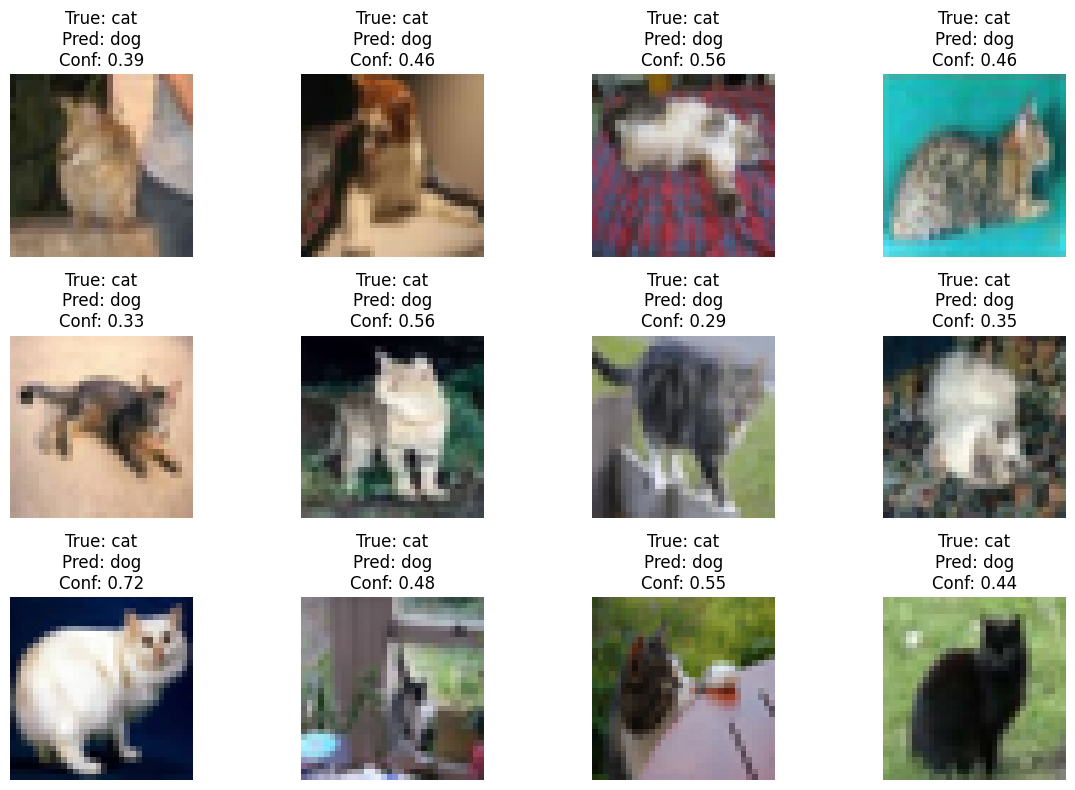

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for i in range(min(12, len(cat_dog_errors))):
    image = cat_dog_errors[i]["image"]

    # CHW → HWC
    image = image.permute(1, 2, 0)

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(
        f"True: {class_names[cat_dog_errors[i]['true']]}\n"
        f"Pred: {class_names[cat_dog_errors[i]['predicted']]}\n"
        f"Conf: {cat_dog_errors[i]['confidence']:.2f}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [58]:
dog_cat_errors = [
    x for x in wrong_examples
    if x["true"] == 5 and x["predicted"] == 3
]

print("Dog → Cat errors:", len(dog_cat_errors))

Dog → Cat errors: 163


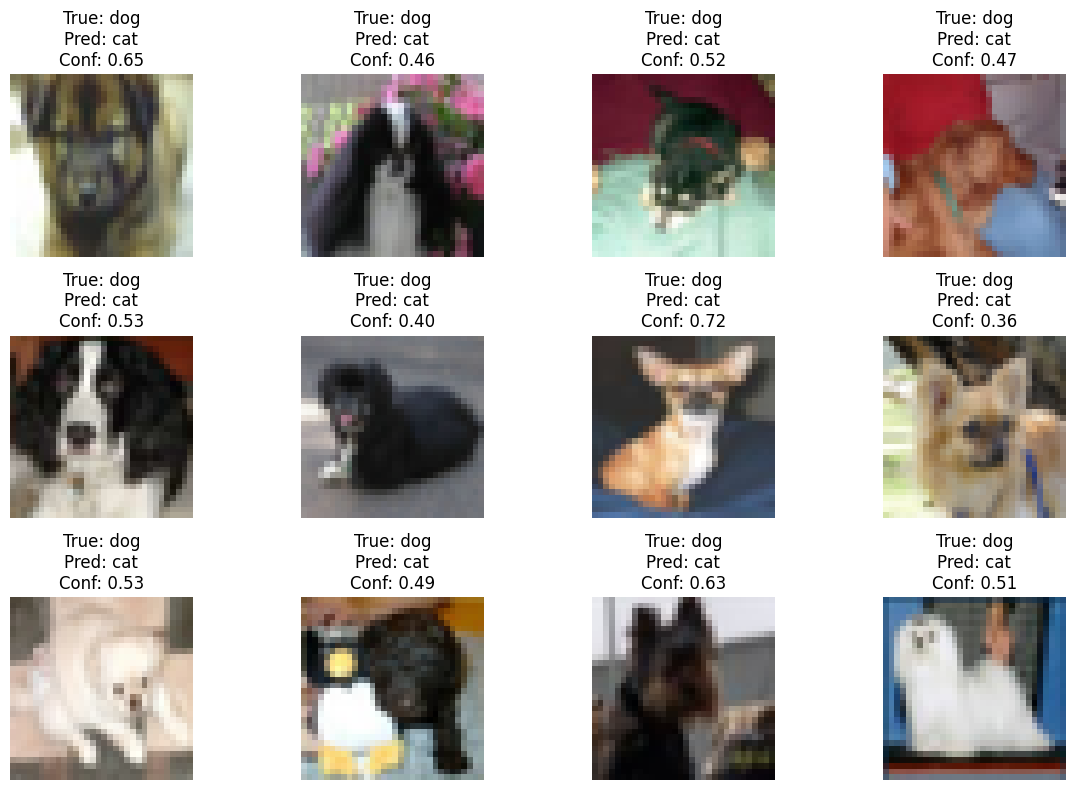

In [59]:
plt.figure(figsize=(12, 8))

for i in range(min(12, len(dog_cat_errors))):
    image = dog_cat_errors[i]["image"]

    # CHW → HWC
    image = image.permute(1, 2, 0)

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(
        f"True: {class_names[dog_cat_errors[i]['true']]}\n"
        f"Pred: {class_names[dog_cat_errors[i]['predicted']]}\n"
        f"Conf: {dog_cat_errors[i]['confidence']:.2f}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [60]:
auto_truck_errors = [
    x for x in wrong_examples
    if x["true"] == 1 and x["predicted"] == 9
]

print("Automobile → Truck errors:", len(auto_truck_errors))

Automobile → Truck errors: 94


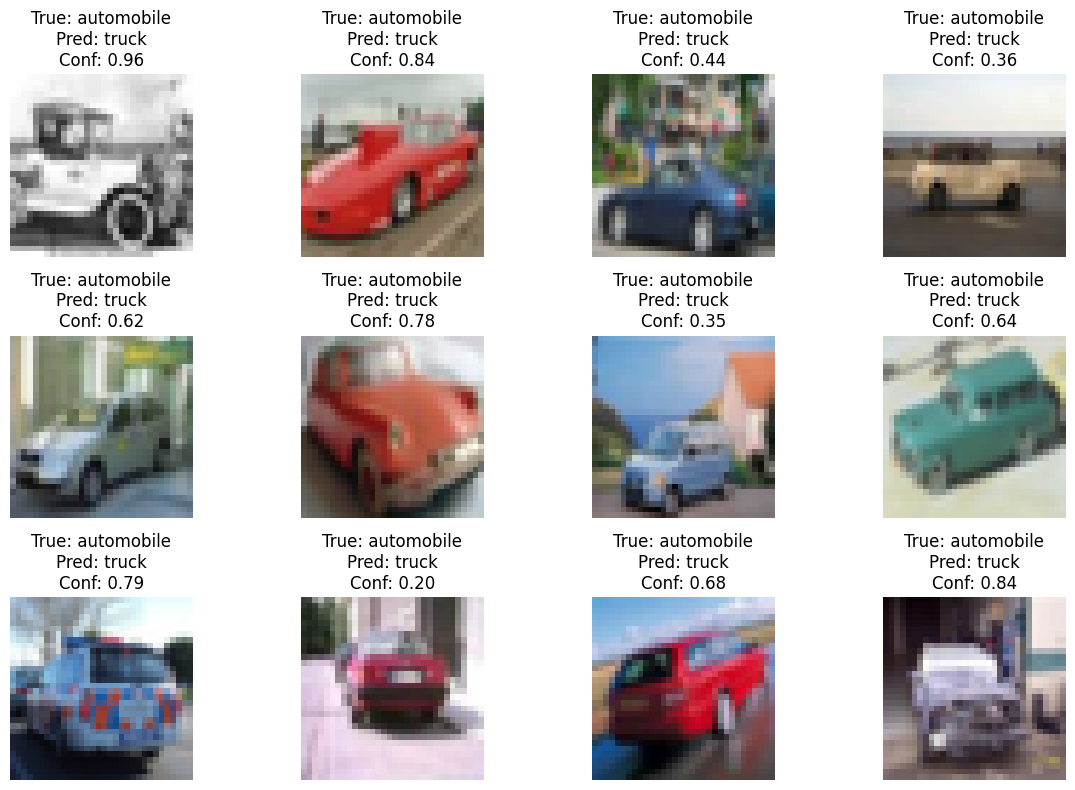

In [61]:
plt.figure(figsize=(12, 8))

for i in range(min(12, len(auto_truck_errors))):
    image = auto_truck_errors[i]["image"]

    # CHW → HWC
    image = image.permute(1, 2, 0)

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(
        f"True: {class_names[auto_truck_errors[i]['true']]}\n"
        f"Pred: {class_names[auto_truck_errors[i]['predicted']]}\n"
        f"Conf: {auto_truck_errors[i]['confidence']:.2f}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [62]:
most_confident_wrong = sorted(
    wrong_examples,
    key=lambda x: x["confidence"],
    reverse=True
)

print("Top 10 most confident wrong predictions:\n")

for i, x in enumerate(most_confident_wrong[:10]):
    print(
        f"{i+1}. True: {class_names[x['true']]:10s} | "
        f"Pred: {class_names[x['predicted']]:10s} | "
        f"Confidence: {x['confidence']:.4f}"
    )

Top 10 most confident wrong predictions:

1. True: bird       | Pred: frog       | Confidence: 0.9920
2. True: cat        | Pred: truck      | Confidence: 0.9895
3. True: automobile | Pred: truck      | Confidence: 0.9891
4. True: automobile | Pred: truck      | Confidence: 0.9884
5. True: deer       | Pred: horse      | Confidence: 0.9873
6. True: dog        | Pred: frog       | Confidence: 0.9866
7. True: automobile | Pred: truck      | Confidence: 0.9824
8. True: ship       | Pred: automobile | Confidence: 0.9821
9. True: bird       | Pred: airplane   | Confidence: 0.9793
10. True: bird       | Pred: airplane   | Confidence: 0.9792


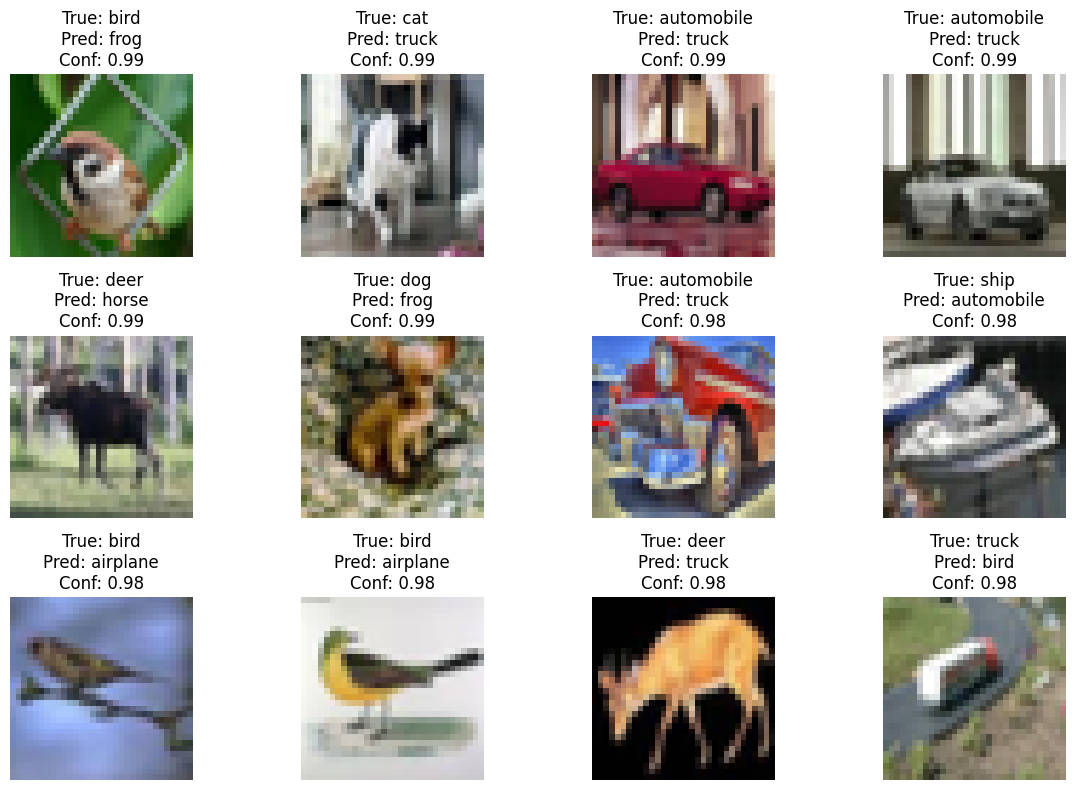

In [63]:
plt.figure(figsize=(12, 8))

for i in range(min(12, len(most_confident_wrong))):
    x = most_confident_wrong[i]

    image = x["image"].permute(1, 2, 0)

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)

    plt.title(
        f"True: {class_names[x['true']]}\n"
        f"Pred: {class_names[x['predicted']]}\n"
        f"Conf: {x['confidence']:.2f}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [64]:
checkpoint_lr_cnn.eval()

correct_confidences = []
wrong_confidences = []

with torch.no_grad():
    for images, labels in test_loader_clean:
        images = images.to(device)
        labels = labels.to(device)

        outputs = checkpoint_lr_cnn(images)
        probabilities = torch.softmax(outputs, dim=1)

        predictions = outputs.argmax(dim=1)
        confidences = probabilities.max(dim=1).values

        for i in range(len(labels)):
            if predictions[i] == labels[i]:
                correct_confidences.append(confidences[i].item())
            else:
                wrong_confidences.append(confidences[i].item())

print("Average confidence - correct:",
      sum(correct_confidences) / len(correct_confidences))

print("Average confidence - wrong:",
      sum(wrong_confidences) / len(wrong_confidences))

print("Highest confidence - wrong:",
      max(wrong_confidences))

Average confidence - correct: 0.7374731734196862
Average confidence - wrong: 0.516389475815061
Highest confidence - wrong: 0.9920286536216736


In [65]:
import torch

x = torch.randn(1, 3, 8, 8)

print("Input shape:", x.shape)

Input shape: torch.Size([1, 3, 8, 8])


In [66]:
import torch.nn as nn

conv1 = nn.Conv2d(3, 3, kernel_size=3, padding=1)
relu = nn.ReLU()
conv2 = nn.Conv2d(3, 3, kernel_size=3, padding=1)

In [67]:
F_x = conv2(relu(conv1(x)))

print("x shape:", x.shape)
print("F(x) shape:", F_x.shape)

x shape: torch.Size([1, 3, 8, 8])
F(x) shape: torch.Size([1, 3, 8, 8])


In [68]:
output = F_x + x

print("Output shape:", output.shape)

Output shape: torch.Size([1, 3, 8, 8])


In [69]:
class ResidualBlock(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 3, 3, padding=1)
        self.relu = nn.ReLU()
        self.conv2 = nn.Conv2d(3, 3, 3, padding=1)

    def forward(self, x):
        identity = x

        out = self.conv1(x)
        out = self.relu(out)
        out = self.conv2(out)

        out = out + identity

        return out

In [70]:
block = ResidualBlock()

x = torch.randn(1, 3, 8, 8)

output = block(x)

print("Input:", x.shape)
print("Output:", output.shape)

Input: torch.Size([1, 3, 8, 8])
Output: torch.Size([1, 3, 8, 8])


In [71]:
projection = nn.Conv2d(3, 16, kernel_size=1)

x = torch.randn(1, 3, 8, 8)

shortcut = projection(x)

print("Input:", x.shape)
print("Shortcut:", shortcut.shape)

Input: torch.Size([1, 3, 8, 8])
Shortcut: torch.Size([1, 16, 8, 8])


In [72]:
class ResidualBlock(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.conv2 = nn.Conv2d(16, 16, kernel_size=3, padding=1)

        self.projection = nn.Conv2d(3, 16, kernel_size=1)

    def forward(self, x):
        shortcut = self.projection(x)

        out = self.conv1(x)
        out = self.relu(out)
        out = self.conv2(out)

        out = out + shortcut
        out = self.relu(out)

        return out

In [73]:
block = ResidualBlock()

x = torch.randn(1, 3, 8, 8)

output = block(x)

print("Input:", x.shape)
print("Output:", output.shape)

Input: torch.Size([1, 3, 8, 8])
Output: torch.Size([1, 16, 8, 8])


In [74]:
class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()

        self.conv1 = nn.Conv2d(
            channels, channels,
            kernel_size=3,
            padding=1
        )

        self.bn1 = nn.BatchNorm2d(channels)

        self.relu = nn.ReLU()

        self.conv2 = nn.Conv2d(
            channels, channels,
            kernel_size=3,
            padding=1
        )

        self.bn2 = nn.BatchNorm2d(channels)

    def forward(self, x):

        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out = out + identity

        out = self.relu(out)

        return out

In [75]:
block = ResidualBlock(32)

x = torch.randn(1, 32, 32, 32)

output = block(x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([1, 32, 32, 32])
Output shape: torch.Size([1, 32, 32, 32])


In [76]:
class ResidualBlockDownsample(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            stride=2,
            padding=1
        )

        self.bn1 = nn.BatchNorm2d(out_channels)

        self.relu = nn.ReLU()

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            stride=1,
            padding=1
        )

        self.bn2 = nn.BatchNorm2d(out_channels)

        self.projection = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=1,
            stride=2
        )

        self.bn_projection = nn.BatchNorm2d(out_channels)

    def forward(self, x):

        identity = self.projection(x)
        identity = self.bn_projection(identity)

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out = out + identity
        out = self.relu(out)

        return out

In [77]:
block_down = ResidualBlockDownsample(32, 64)

x = torch.randn(1, 32, 32, 32)

output = block_down(x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([1, 32, 32, 32])
Output shape: torch.Size([1, 64, 16, 16])


In [78]:
x = torch.randn(1, 128, 8, 8)

gap = nn.AdaptiveAvgPool2d((1, 1))

output = gap(x)

print("Before GAP:", x.shape)
print("After GAP:", output.shape)

Before GAP: torch.Size([1, 128, 8, 8])
After GAP: torch.Size([1, 128, 1, 1])


In [79]:
flattened = torch.flatten(output, start_dim=1)

print("Flattened:", flattened.shape)

Flattened: torch.Size([1, 128])


In [80]:
x = torch.randn(1, 128, 8, 8)

gap = nn.AdaptiveAvgPool2d((1, 1))

output = gap(x)

print("Before GAP:", x.shape)
print("After GAP:", output.shape)

flattened = torch.flatten(output, start_dim=1)

print("Flattened:", flattened.shape)

Before GAP: torch.Size([1, 128, 8, 8])
After GAP: torch.Size([1, 128, 1, 1])
Flattened: torch.Size([1, 128])


In [81]:
class MiniResNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU()
        )

        self.block1 = ResidualBlock(32)
        self.block2 = ResidualBlock(32)

        self.block3 = ResidualBlockDownsample(32, 64)

        self.block4 = ResidualBlock(64)

        self.block5 = ResidualBlockDownsample(64, 128)

        self.block6 = ResidualBlock(128)

        self.gap = nn.AdaptiveAvgPool2d((1, 1))

        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):

        x = self.stem(x)

        x = self.block1(x)
        x = self.block2(x)

        x = self.block3(x)

        x = self.block4(x)

        x = self.block5(x)

        x = self.block6(x)

        x = self.gap(x)

        x = torch.flatten(x, start_dim=1)

        x = self.fc(x)

        return x

In [82]:
model_resnet = MiniResNet().to(device)

print(model_resnet)

MiniResNet(
  (stem): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
  )
  (block1): ResidualBlock(
    (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU()
    (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (block2): ResidualBlock(
    (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU()
    (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (

In [83]:
total_params = sum(
    p.numel() for p in model_resnet.parameters()
)

print("Total parameters:", total_params)

Total parameters: 697738


In [84]:
images, labels = next(iter(train_loader))

images = images.to(device)

outputs = model_resnet(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([64, 3, 32, 32])
Output shape: torch.Size([64, 10])


In [85]:
criterion_resnet = nn.CrossEntropyLoss()

optimizer_resnet = torch.optim.SGD(
    model_resnet.parameters(),
    lr=0.01
)

In [86]:
scheduler_resnet = torch.optim.lr_scheduler.StepLR(
    optimizer_resnet,
    step_size=3,
    gamma=0.1
)

In [87]:
for epoch in range(10):

    model_resnet.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_resnet.zero_grad()

        outputs = model_resnet(images)

        loss = criterion_resnet(outputs, labels)

        loss.backward()

        optimizer_resnet.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # Validation
    model_resnet.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_resnet(images)

            loss = criterion_resnet(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_total / val_total
    val_acc = val_correct / val_total

    print(
        f"Epoch {epoch+1} | "
        f"LR {optimizer_resnet.param_groups[0]['lr']:.5f} | "
        f"Train Loss {train_loss:.4f} | "
        f"Train Acc {train_acc:.2%} | "
        f"Val Loss {val_loss:.4f} | "
        f"Val Acc {val_acc:.2%}"
    )

    scheduler_resnet.step()

Epoch 1 | LR 0.01000 | Train Loss 1.5779 | Train Acc 42.09% | Val Loss 2.1166 | Val Acc 28.92%
Epoch 2 | LR 0.01000 | Train Loss 1.1810 | Train Acc 57.47% | Val Loss 1.2550 | Val Acc 55.52%
Epoch 3 | LR 0.01000 | Train Loss 0.9816 | Train Acc 64.79% | Val Loss 4.3042 | Val Acc 22.18%
Epoch 4 | LR 0.00100 | Train Loss 0.8107 | Train Acc 71.72% | Val Loss 0.8290 | Val Acc 70.44%
Epoch 5 | LR 0.00100 | Train Loss 0.7753 | Train Acc 72.94% | Val Loss 0.8009 | Val Acc 71.28%
Epoch 6 | LR 0.00100 | Train Loss 0.7512 | Train Acc 73.64% | Val Loss 0.8285 | Val Acc 70.56%
Epoch 7 | LR 0.00010 | Train Loss 0.7308 | Train Acc 74.50% | Val Loss 0.7838 | Val Acc 72.34%
Epoch 8 | LR 0.00010 | Train Loss 0.7254 | Train Acc 74.58% | Val Loss 0.7807 | Val Acc 71.96%
Epoch 9 | LR 0.00010 | Train Loss 0.7237 | Train Acc 74.70% | Val Loss 0.7771 | Val Acc 72.20%
Epoch 10 | LR 0.00001 | Train Loss 0.7209 | Train Acc 74.99% | Val Loss 0.7812 | Val Acc 72.18%


In [88]:
model_resnet = MiniResNet(num_classes=10).to(device)

criterion_resnet = nn.CrossEntropyLoss()

optimizer_resnet = torch.optim.SGD(
    model_resnet.parameters(),
    lr=0.01
)

scheduler_resnet = torch.optim.lr_scheduler.StepLR(
    optimizer_resnet,
    step_size=3,
    gamma=0.1
)

In [89]:
import copy

best_val_acc = 0.0
best_epoch = 0
best_state = None

In [90]:
model_resnet = MiniResNet(num_classes=10).to(device)

criterion_resnet = nn.CrossEntropyLoss()

optimizer_resnet = torch.optim.SGD(
    model_resnet.parameters(),
    lr=0.01
)

scheduler_resnet = torch.optim.lr_scheduler.StepLR(
    optimizer_resnet,
    step_size=3,
    gamma=0.1
)

import copy

best_val_acc = 0.0
best_epoch = 0
best_state = None

print("Model parameters:", sum(p.numel() for p in model_resnet.parameters()))

Model parameters: 697738


In [91]:
for epoch in range(10):

    # =========================
    # Training
    # =========================
    model_resnet.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_resnet.zero_grad()

        outputs = model_resnet(images)
        loss = criterion_resnet(outputs, labels)

        loss.backward()
        optimizer_resnet.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total


    # =========================
    # Validation
    # =========================
    model_resnet.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model_resnet(images)
            loss = criterion_resnet(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total


    # =========================
    # Checkpoint
    # =========================
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch + 1
        best_state = copy.deepcopy(model_resnet.state_dict())

        marker = " ⭐ BEST"
    else:
        marker = ""


    # =========================
    # Learning rate
    # =========================
    current_lr = optimizer_resnet.param_groups[0]["lr"]

    print(
        f"Epoch {epoch+1:2d} | "
        f"LR {current_lr:.5f} | "
        f"Train Loss {train_loss:.4f} | "
        f"Train Acc {train_acc*100:.2f}% | "
        f"Val Loss {val_loss:.4f} | "
        f"Val Acc {val_acc*100:.2f}%"
        f"{marker}"
    )

    scheduler_resnet.step()

Epoch  1 | LR 0.01000 | Train Loss 1.5414 | Train Acc 43.72% | Val Loss 1.4039 | Val Acc 49.72% ⭐ BEST
Epoch  2 | LR 0.01000 | Train Loss 1.1485 | Train Acc 58.74% | Val Loss 3.2558 | Val Acc 33.16%
Epoch  3 | LR 0.01000 | Train Loss 0.9610 | Train Acc 65.70% | Val Loss 1.3327 | Val Acc 54.80% ⭐ BEST
Epoch  4 | LR 0.00100 | Train Loss 0.7935 | Train Acc 72.24% | Val Loss 0.8177 | Val Acc 71.64% ⭐ BEST
Epoch  5 | LR 0.00100 | Train Loss 0.7622 | Train Acc 73.41% | Val Loss 0.8068 | Val Acc 71.98% ⭐ BEST
Epoch  6 | LR 0.00100 | Train Loss 0.7418 | Train Acc 74.01% | Val Loss 0.7947 | Val Acc 72.12% ⭐ BEST
Epoch  7 | LR 0.00010 | Train Loss 0.7218 | Train Acc 74.98% | Val Loss 0.7774 | Val Acc 73.18% ⭐ BEST
Epoch  8 | LR 0.00010 | Train Loss 0.7172 | Train Acc 75.13% | Val Loss 0.7715 | Val Acc 73.12%
Epoch  9 | LR 0.00010 | Train Loss 0.7145 | Train Acc 75.18% | Val Loss 0.7694 | Val Acc 73.38% ⭐ BEST
Epoch 10 | LR 0.00001 | Train Loss 0.7138 | Train Acc 75.19% | Val Loss 0.7678 | Val Ac

In [92]:
model_resnet.load_state_dict(best_state)

print("Loaded best epoch:", best_epoch)
print("Best validation accuracy:", best_val_acc)

Loaded best epoch: 9
Best validation accuracy: 0.7338


In [93]:
model_resnet.eval()

test_loss = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():

    for images, labels in test_loader_clean:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_resnet(images)
        loss = criterion_resnet(outputs, labels)

        test_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        test_correct += (predictions == labels).sum().item()
        test_total += labels.size(0)

test_loss /= test_total
test_acc = test_correct / test_total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc*100:.2f}%")
print(f"Correct: {test_correct}")
print(f"Wrong: {test_total - test_correct}")
print(f"Total: {test_total}")

Test Loss: 0.7757
Test Accuracy: 72.97%
Correct: 7297
Wrong: 2703
Total: 10000


In [94]:
from sklearn.metrics import confusion_matrix
import numpy as np

model_resnet.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader_clean:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_resnet(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm_resnet = confusion_matrix(all_labels, all_predictions)

print(cm_resnet)

[[755  27  55  11  11   5  11  13  75  37]
 [ 23 871   0   3   2   2   6   3  18  72]
 [ 89   5 580  67  97  44  73  32   7   6]
 [ 26   9  66 537  55 177  80  19  17  14]
 [ 22   1  62  51 653  38  73  82  15   3]
 [ 13   4  35 198  59 620  22  37   8   4]
 [ 11   4  51  60  29  18 815   5   7   0]
 [ 19   1  48  29  82  62   6 731   1  21]
 [ 58  26   4   8   8   6   2   0 866  22]
 [ 30  60   5   4   3   0   5   7  17 869]]


In [95]:
cm_normalized = cm_resnet.astype(float) / cm_resnet.sum(axis=1, keepdims=True)

np.set_printoptions(precision=3, suppress=True)

print(cm_normalized)

[[0.755 0.027 0.055 0.011 0.011 0.005 0.011 0.013 0.075 0.037]
 [0.023 0.871 0.    0.003 0.002 0.002 0.006 0.003 0.018 0.072]
 [0.089 0.005 0.58  0.067 0.097 0.044 0.073 0.032 0.007 0.006]
 [0.026 0.009 0.066 0.537 0.055 0.177 0.08  0.019 0.017 0.014]
 [0.022 0.001 0.062 0.051 0.653 0.038 0.073 0.082 0.015 0.003]
 [0.013 0.004 0.035 0.198 0.059 0.62  0.022 0.037 0.008 0.004]
 [0.011 0.004 0.051 0.06  0.029 0.018 0.815 0.005 0.007 0.   ]
 [0.019 0.001 0.048 0.029 0.082 0.062 0.006 0.731 0.001 0.021]
 [0.058 0.026 0.004 0.008 0.008 0.006 0.002 0.    0.866 0.022]
 [0.03  0.06  0.005 0.004 0.003 0.    0.005 0.007 0.017 0.869]]


In [96]:
checkpoint_resnet = model_resnet

checkpoint_resnet.eval()

class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

wrong_examples_resnet = []

with torch.no_grad():

    for images, labels in test_loader_clean:

        images = images.to(device)
        labels = labels.to(device)

        outputs = checkpoint_resnet(images)

        probabilities = torch.softmax(outputs, dim=1)

        predictions = outputs.argmax(dim=1)

        confidences = probabilities.max(dim=1).values

        for i in range(len(labels)):

            if predictions[i] != labels[i]:

                wrong_examples_resnet.append({
                    "image": images[i].cpu(),
                    "true": labels[i].item(),
                    "predicted": predictions[i].item(),
                    "confidence": confidences[i].item()
                })

print("Total wrong predictions:", len(wrong_examples_resnet))

Total wrong predictions: 2703


In [97]:
wrong_examples_resnet_sorted = sorted(
    wrong_examples_resnet,
    key=lambda x: x["confidence"],
    reverse=True
)

print("Top 10 most confident wrong predictions:\n")

for i, example in enumerate(wrong_examples_resnet_sorted[:10], start=1):

    true_class = class_names[example["true"]]
    predicted_class = class_names[example["predicted"]]
    confidence = example["confidence"]

    print(
        f"{i}. "
        f"{true_class} → {predicted_class} | "
        f"Confidence: {confidence:.4f}"
    )

Top 10 most confident wrong predictions:

1. automobile → truck | Confidence: 0.9953
2. airplane → automobile | Confidence: 0.9940
3. airplane → automobile | Confidence: 0.9926
4. airplane → ship | Confidence: 0.9922
5. truck → ship | Confidence: 0.9863
6. automobile → truck | Confidence: 0.9855
7. truck → automobile | Confidence: 0.9846
8. airplane → automobile | Confidence: 0.9810
9. truck → automobile | Confidence: 0.9802
10. airplane → ship | Confidence: 0.9793


In [98]:
correct_confidences = []
wrong_confidences = []

model_resnet.eval()

with torch.no_grad():

    for images, labels in test_loader_clean:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model_resnet(images)

        probabilities = torch.softmax(outputs, dim=1)

        predictions = outputs.argmax(dim=1)

        confidences = probabilities.max(dim=1).values

        correct_mask = predictions == labels
        wrong_mask = predictions != labels

        correct_confidences.extend(
            confidences[correct_mask].cpu().tolist()
        )

        wrong_confidences.extend(
            confidences[wrong_mask].cpu().tolist()
        )

avg_correct_conf = np.mean(correct_confidences)
avg_wrong_conf = np.mean(wrong_confidences)
max_wrong_conf = np.max(wrong_confidences)

print(f"Average confidence - correct: {avg_correct_conf:.4f}")
print(f"Average confidence - wrong:   {avg_wrong_conf:.4f}")
print(f"Confidence gap:               {avg_correct_conf - avg_wrong_conf:.4f}")
print(f"Highest wrong confidence:      {max_wrong_conf:.4f}")

Average confidence - correct: 0.7695
Average confidence - wrong:   0.5233
Confidence gap:               0.2461
Highest wrong confidence:      0.9953


In [99]:
all_confidences = []
all_correct = []

model_resnet.eval()

with torch.no_grad():

    for images, labels in test_loader_clean:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model_resnet(images)

        probabilities = torch.softmax(outputs, dim=1)

        predictions = outputs.argmax(dim=1)

        confidences = probabilities.max(dim=1).values

        correct = predictions == labels

        all_confidences.extend(confidences.cpu().tolist())
        all_correct.extend(correct.cpu().tolist())


all_confidences = np.array(all_confidences)
all_correct = np.array(all_correct)


bins = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

for lower, upper in zip(bins[:-1], bins[1:]):

    mask = (
        (all_confidences >= lower) &
        (all_confidences < upper)
    )

    count = mask.sum()

    if count > 0:
        accuracy = all_correct[mask].mean()

        print(
            f"{lower:.0%}–{upper:.0%}: "
            f"{count} predictions | "
            f"Accuracy: {accuracy:.2%}"
        )

0%–20%: 13 predictions | Accuracy: 30.77%
20%–40%: 1162 predictions | Accuracy: 36.40%
40%–60%: 2462 predictions | Accuracy: 53.86%
60%–80%: 2217 predictions | Accuracy: 73.48%
80%–100%: 4146 predictions | Accuracy: 94.43%


In [100]:
import torchvision.models as models

model = models.resnet18(weights="DEFAULT")

print(model)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 240MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [101]:
print("FC input features:", model.fc.in_features)
print("FC output features:", model.fc.out_features)

print("Total parameters:",
      sum(p.numel() for p in model.parameters()))

FC input features: 512
FC output features: 1000
Total parameters: 11689512


In [102]:
for param in model.parameters():
    param.requires_grad = False

In [103]:
trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 11689512
Trainable parameters: 0


In [104]:
model.fc = nn.Linear(model.fc.in_features, 10)

In [105]:
print(model.fc)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Linear(in_features=512, out_features=10, bias=True)
Total parameters: 11181642
Trainable parameters: 5130


In [106]:
images, labels = next(iter(test_loader_clean))

images = images.to(device)
labels = labels.to(device)

outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Labels shape:", labels.shape)

RuntimeError: Input type (torch.cuda.FloatTensor) and weight type (torch.FloatTensor) should be the same

In [107]:
model = model.to(device)

In [108]:
print("Model device:", next(model.parameters()).device)
print("Image device:", images.device)

Model device: cuda:0
Image device: cuda:0


In [109]:
outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Labels shape:", labels.shape)

Input shape: torch.Size([64, 3, 32, 32])
Output shape: torch.Size([64, 10])
Labels shape: torch.Size([64])


In [110]:
from torchvision import transforms

imagenet_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [111]:
transfer_train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=imagenet_transform
)

transfer_test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=False,
    transform=imagenet_transform
)

In [112]:
train_size = 45000
val_size = 5000

generator = torch.Generator().manual_seed(42)

transfer_train_subset, transfer_val_subset = random_split(
    transfer_train_dataset,
    [train_size, val_size],
    generator=generator
)

transfer_train_loader = DataLoader(
    transfer_train_subset,
    batch_size=64,
    shuffle=True
)

transfer_val_loader = DataLoader(
    transfer_val_subset,
    batch_size=64,
    shuffle=False
)

transfer_test_loader = DataLoader(
    transfer_test_dataset,
    batch_size=64,
    shuffle=False
)

In [113]:
images, labels = next(iter(transfer_train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Min:", images.min().item())
print("Max:", images.max().item())

Images: torch.Size([64, 3, 32, 32])
Labels: torch.Size([64])
Min: -2.1179039478302
Max: 2.640000104904175


In [114]:
criterion_transfer = nn.CrossEntropyLoss()

optimizer_transfer = torch.optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

In [115]:
trainable_params = [
    name for name, param in model.named_parameters()
    if param.requires_grad
]

print("Trainable parameter tensors:")
for name in trainable_params:
    print(name)

Trainable parameter tensors:
fc.weight
fc.bias


In [116]:
import copy

best_val_acc = 0.0
best_epoch = 0
best_state = None

for epoch in range(5):

    # -----------------
    # Training
    # -----------------
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in transfer_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_transfer.zero_grad()

        outputs = model(images)
        loss = criterion_transfer(outputs, labels)

        loss.backward()
        optimizer_transfer.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # -----------------
    # Validation
    # -----------------
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in transfer_val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion_transfer(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    # -----------------
    # Checkpoint
    # -----------------
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch + 1
        best_state = copy.deepcopy(model.state_dict())

        marker = " ⭐ BEST"
    else:
        marker = ""

    print(
        f"Epoch {epoch+1} | "
        f"Train Loss {train_loss:.4f} | "
        f"Train Acc {train_acc:.2%} | "
        f"Val Loss {val_loss:.4f} | "
        f"Val Acc {val_acc:.2%}"
        f"{marker}"
    )

print()
print("Best epoch:", best_epoch)
print("Best validation accuracy:", f"{best_val_acc:.2%}")

Epoch 1 | Train Loss 1.7397 | Train Acc 39.12% | Val Loss 1.6114 | Val Acc 44.00% ⭐ BEST
Epoch 2 | Train Loss 1.6002 | Train Acc 44.02% | Val Loss 1.5900 | Val Acc 45.26% ⭐ BEST
Epoch 3 | Train Loss 1.5778 | Train Acc 45.03% | Val Loss 1.5699 | Val Acc 45.36% ⭐ BEST
Epoch 4 | Train Loss 1.5688 | Train Acc 45.48% | Val Loss 1.5614 | Val Acc 46.20% ⭐ BEST
Epoch 5 | Train Loss 1.5701 | Train Acc 45.39% | Val Loss 1.6190 | Val Acc 44.00%

Best epoch: 4
Best validation accuracy: 46.20%


In [117]:
model.load_state_dict(best_state)

print("Loaded best feature-extraction epoch:", best_epoch)
print("Best validation accuracy:", f"{best_val_acc:.2%}")

Loaded best feature-extraction epoch: 4
Best validation accuracy: 46.20%


In [118]:
for name, param in model.named_parameters():

    if name.startswith("layer3"):
        param.requires_grad = True

    elif name.startswith("layer4"):
        param.requires_grad = True

    elif name.startswith("fc"):
        param.requires_grad = True

    else:
        param.requires_grad = False

In [119]:
trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", trainable_params)

for name, param in model.named_parameters():
    if param.requires_grad:
        print(name)

Trainable parameters: 10498570
layer3.0.conv1.weight
layer3.0.bn1.weight
layer3.0.bn1.bias
layer3.0.conv2.weight
layer3.0.bn2.weight
layer3.0.bn2.bias
layer3.0.downsample.0.weight
layer3.0.downsample.1.weight
layer3.0.downsample.1.bias
layer3.1.conv1.weight
layer3.1.bn1.weight
layer3.1.bn1.bias
layer3.1.conv2.weight
layer3.1.bn2.weight
layer3.1.bn2.bias
layer4.0.conv1.weight
layer4.0.bn1.weight
layer4.0.bn1.bias
layer4.0.conv2.weight
layer4.0.bn2.weight
layer4.0.bn2.bias
layer4.0.downsample.0.weight
layer4.0.downsample.1.weight
layer4.0.downsample.1.bias
layer4.1.conv1.weight
layer4.1.bn1.weight
layer4.1.bn1.bias
layer4.1.conv2.weight
layer4.1.bn2.weight
layer4.1.bn2.bias
fc.weight
fc.bias


In [121]:
criterion_finetune = nn.CrossEntropyLoss()

optimizer_finetune = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.0001
)

In [122]:
print("Optimizer created.")
print("Learning rate:", optimizer_finetune.param_groups[0]["lr"])

Optimizer created.
Learning rate: 0.0001


In [123]:
import copy

best_finetune_val_acc = 0.0
best_finetune_epoch = 0
best_finetune_state = None

for epoch in range(5):

    # -----------------
    # Training
    # -----------------
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in transfer_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_finetune.zero_grad()

        outputs = model(images)
        loss = criterion_finetune(outputs, labels)

        loss.backward()
        optimizer_finetune.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # -----------------
    # Validation
    # -----------------
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in transfer_val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion_finetune(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    # -----------------
    # Checkpoint
    # -----------------
    if val_acc > best_finetune_val_acc:
        best_finetune_val_acc = val_acc
        best_finetune_epoch = epoch + 1
        best_finetune_state = copy.deepcopy(model.state_dict())

        marker = " ⭐ BEST"
    else:
        marker = ""

    print(
        f"Epoch {epoch+1} | "
        f"Train Loss {train_loss:.4f} | "
        f"Train Acc {train_acc:.2%} | "
        f"Val Loss {val_loss:.4f} | "
        f"Val Acc {val_acc:.2%}"
        f"{marker}"
    )

print()
print("Best epoch:", best_finetune_epoch)
print(
    "Best validation accuracy:",
    f"{best_finetune_val_acc:.2%}"
)

Epoch 1 | Train Loss 1.0812 | Train Acc 62.35% | Val Loss 0.8301 | Val Acc 71.54% ⭐ BEST
Epoch 2 | Train Loss 0.7008 | Train Acc 75.70% | Val Loss 0.7486 | Val Acc 73.78% ⭐ BEST
Epoch 3 | Train Loss 0.5211 | Train Acc 81.49% | Val Loss 0.7445 | Val Acc 75.54% ⭐ BEST
Epoch 4 | Train Loss 0.3863 | Train Acc 86.17% | Val Loss 0.7939 | Val Acc 75.48%
Epoch 5 | Train Loss 0.2822 | Train Acc 90.02% | Val Loss 0.8507 | Val Acc 75.94% ⭐ BEST

Best epoch: 5
Best validation accuracy: 75.94%


In [124]:
model.load_state_dict(best_finetune_state)

print("Loaded best fine-tuned model.")
print("Best epoch:", best_finetune_epoch)
print("Best validation accuracy:", f"{best_finetune_val_acc:.2%}")

Loaded best fine-tuned model.
Best epoch: 5
Best validation accuracy: 75.94%


In [125]:
model.eval()

test_loss = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in transfer_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion_finetune(outputs, labels)

        test_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        test_correct += (predictions == labels).sum().item()
        test_total += labels.size(0)

test_loss /= test_total
test_acc = test_correct / test_total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2%}")
print(f"Correct: {test_correct}")
print(f"Wrong: {test_total - test_correct}")

Test Loss: 0.8448
Test Accuracy: 76.02%
Correct: 7602
Wrong: 2398
